# Tentativo 18 · 4. Il confronto: quanto bene si prevede il punteggio esatto?

Tutte le configurazioni (modello, regressore o classificatore, condizione dei dati) si valutano sul punteggio vero,
senza classi:
- **MAE**: di quanti punti si sbaglia in media; **RMSE**: come il MAE ma pesa di più gli errori grandi;
- **R²**: quanta parte della variabilità dei punteggi si spiega (0 = come dire sempre la media, 1 = perfetto);
- **Spearman**: se l'ordine delle testate è giusto; **Pearson**: se il legame è lineare.

Ogni misura per **articolo singolo** (ogni articolo contro il punteggio della sua testata) e per **testata** (la media dei
suoi articoli; per la condizione E il vettore medio della testata). Riferimento: **la media del training** (chi prevede
sempre il punteggio medio delle testate di training). I modelli lineari hanno tre split: barre = media, linee = il più
basso e il più alto dei tre; i BERT hanno lo split 1.

In [1]:
T16_DIR = "../16_DataPreparation"
B = 1000                                    # ricampionamenti bootstrap (split 1)
R = 100                                     # ripetizioni per ogni numero di articoli nella curva del DNA

In [2]:
# Parameters
T16_DIR = "/home/fabio.pinelli/John/Tentativo16"


In [3]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

T16 = Path(T16_DIR).expanduser(); sys.path.insert(0, str(T16))
import funzioni as F16                      # il tentativo 16: dataset e cartella dei dati
import punteggio as P

warnings.filterwarnings("ignore")
plt.rcParams.update(F16.STILE_GRAFICI)
BLU, ARANCIO, GRIGIO, CHIARO, VERDE, ROSSO = "#2a78d6", "#eb6834", "#52514e", "#b5b3ab", "#1baf7a", "#b02a2a"
DATI18 = F16.DATI / "tentativi" / "18_PunteggioEsatto"; DATI18.mkdir(parents=True, exist_ok=True)
OUT = Path("Results"); OUT.mkdir(exist_ok=True)
art = pd.read_csv(F16.DATASET / "articoli.csv.gz")
t = pd.read_csv(F16.DATASET / "testate.csv", index_col="domain")
print(f"{len(art):,} articoli di {len(t)} testate")

25,524 articoli di 226 testate


In [4]:
split = pd.read_csv(DATI18 / "split.csv", index_col=0).reindex(t.index)
vero = t.score
pa = [pd.read_csv(OUT / "lineari" / "previsioni_articoli.csv.gz")] if (OUT / "lineari" / "previsioni_articoli.csv.gz").exists() else []
pa += [pd.read_csv(f) for f in sorted((OUT / "bert").glob("*/previsioni.csv.gz"))]
pa = pd.concat(pa, ignore_index=True)
pa["vero"] = vero.reindex(pa.domain).to_numpy(); pa["previsione"] = pd.to_numeric(pa.previsione)
# il riferimento: la media dei punteggi delle testate di training, fold per fold
base = []
for s in split.columns:
    for k in range(1, 6):
        te = split.index[split[s] == k]; m = vero[split[s] != k].mean()
        a = art[art.domain.isin(te)]
        base.append(pd.DataFrame({"article_id": a.article_id, "domain": a.domain, "previsione": m, "modello": "media del training",
                                  "split": s, "condizione": "-", "tipo": "-", "vero": vero.reindex(a.domain).to_numpy()}))
pa = pd.concat([pa] + base, ignore_index=True)
CHIAVI = ["modello", "tipo", "condizione", "split"]
pt = pa.groupby(CHIAVI + ["domain"], as_index=False).previsione.mean()
fE = OUT / "lineari" / "previsioni_testate_E.csv.gz"
if fE.exists():                                  # condizione E: la previsione della testata viene dal suo vettore medio
    e = pd.read_csv(fE); pt = pt.merge(e, on=CHIAVI + ["domain"], how="left", suffixes=("", "_E"))
    pt["previsione"] = pt.previsione_E.fillna(pt.previsione); pt = pt.drop(columns="previsione_E")
pt["vero"] = vero.reindex(pt.domain).to_numpy()
mis = []
for unita, d in [("articolo", pa), ("testata", pt)]:
    for chiave, g in d.groupby(CHIAVI):
        mis.append({**dict(zip(CHIAVI, chiave)), "unità": unita, **P.misure(g.vero, g.previsione)})
mis = pd.DataFrame(mis); mis.to_csv(OUT / "misure_per_split.csv", index=False)
sintesi = mis.drop(columns="split").groupby(["modello", "tipo", "condizione", "unità"]).agg(["mean", "min", "max"])
print(f"{pa[CHIAVI].drop_duplicates().shape[0]} configurazioni × split")

67 configurazioni × split


## 1. Il quadro completo
Una riga per configurazione. **MAE** (più basso è meglio) e **Spearman** (più alto è meglio), per testata e per articolo.
Linea tratteggiata: la media del training.

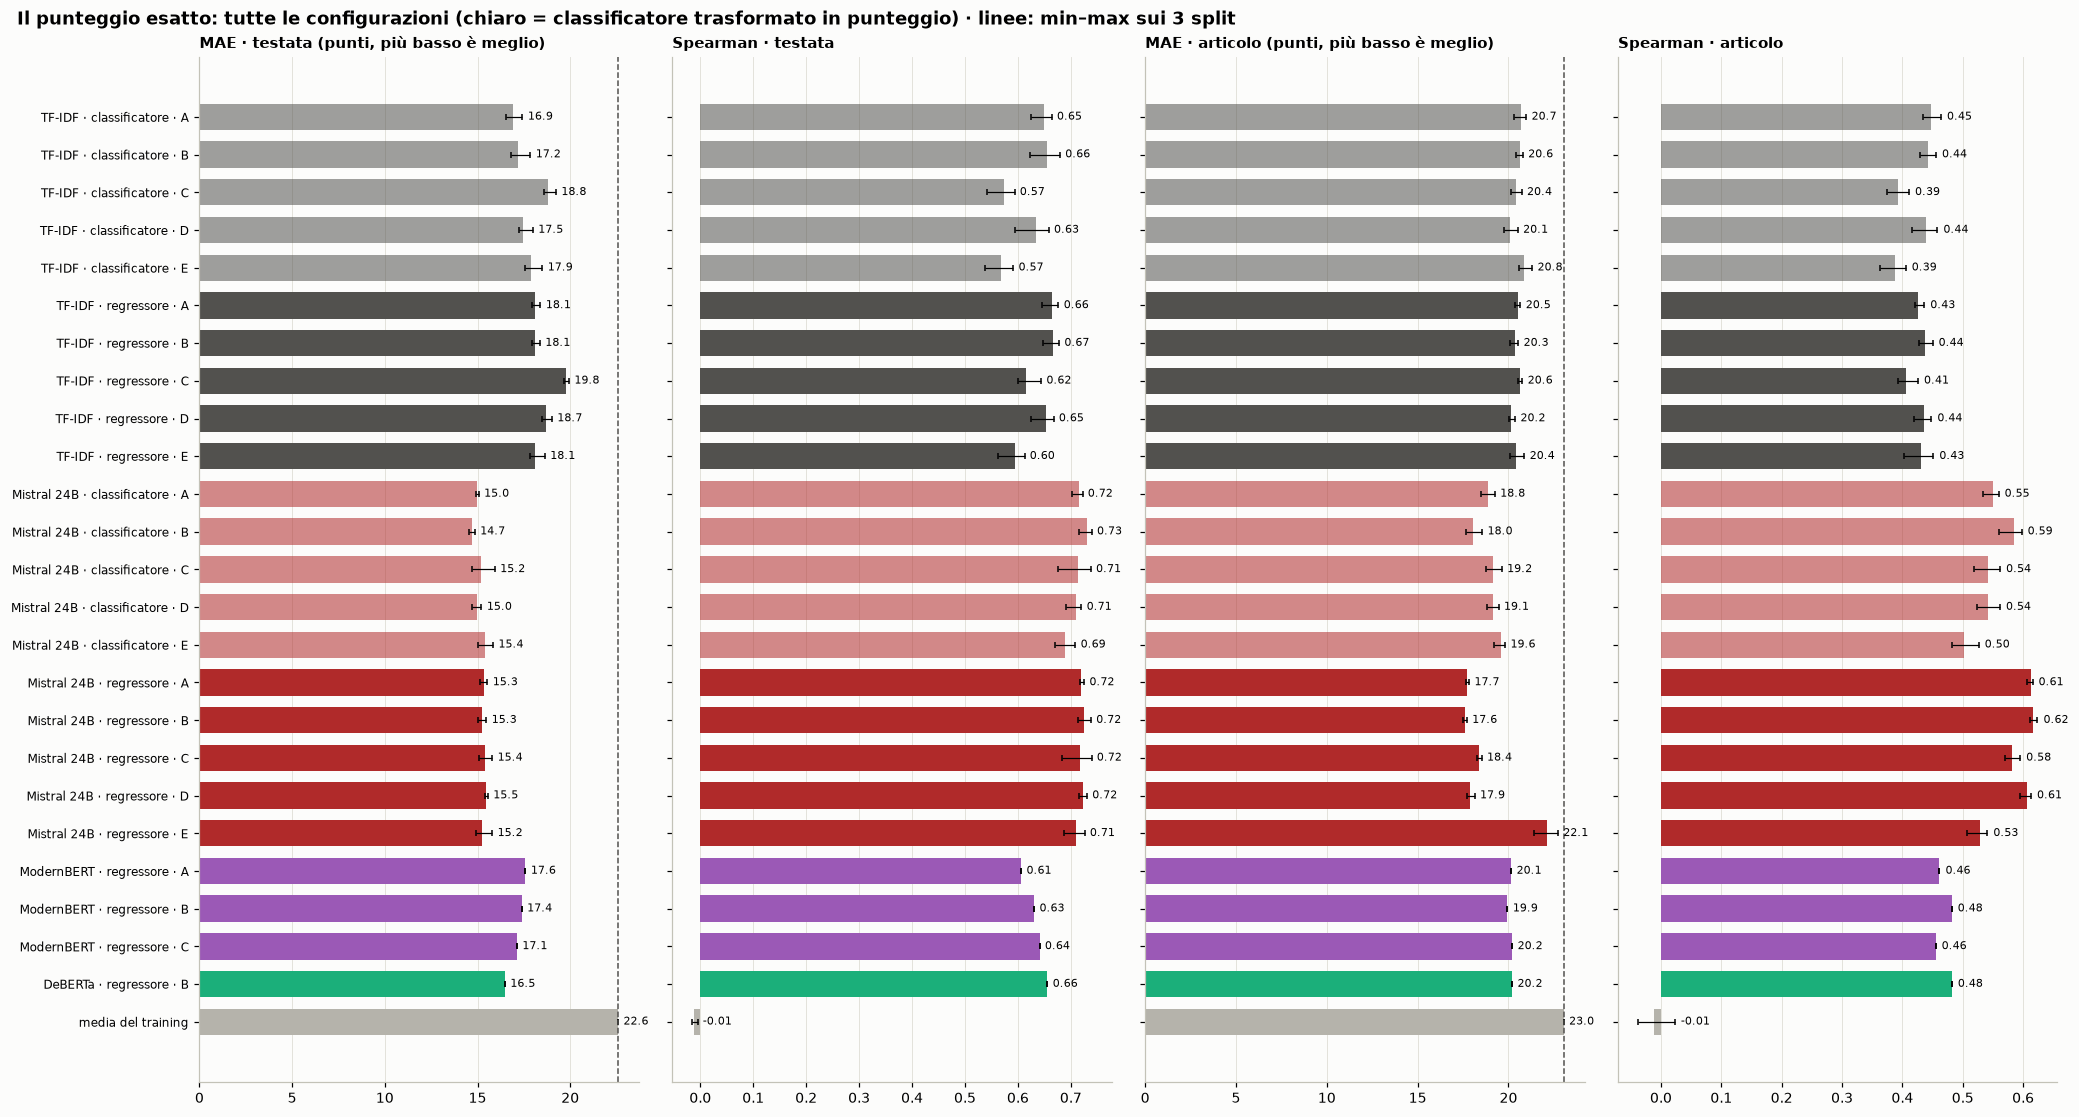

MAE    RMSE     R²  Spearman
modello            tipo           condizione                                 
DeBERTa            regressore     B           16.474  22.309  0.320     0.656
Mistral 24B        classificatore A           14.997  19.324  0.489     0.715
                                  B           14.705  19.062  0.503     0.731
                                  C           15.182  19.725  0.468     0.713
                                  D           14.971  19.535  0.478     0.709
                                  E           15.412  20.235  0.440     0.689
                   regressore     A           15.332  19.427  0.484     0.720
                                  B           15.261  19.428  0.484     0.724
                                  C           15.382  19.615  0.474     0.717
                                  D           15.453  19.604  0.475     0.722
                                  E           15.233  19.888  0.459     0.710
ModernBERT         regressore     A           17.582  21.995  0.339     0.606
                                  B           17.381  21.822  0.349     0.631
                                  C           17.122  21.676  0.358     0.641
TF-IDF             classificatore A           16.929  21.275  0.381     0.649
                                  B           17.184  21.540  0.365     0.656
                                  C           18.808  23.919  0.218     0.573
                                  D           17.479  22.411  0.313     0.633
                                  E           17.910  22.787  0.290     0.567
                   regressore     A           18.104  22.168  0.328     0.664
                                  B           18.100  22.172  0.328     0.666
                                  C           19.764  24.076  0.208     0.616
                                  D           18.714  22.972  0.279     0.653
                                  E           18.108  22.574  0.303     0.595
media del training -              -           22.575  27.049 -0.000    -0.011

In [5]:
COLORE = {"TF-IDF": GRIGIO, "Mistral 24B": ROSSO, "ModernBERT": "#9b59b6", "DeBERTa": VERDE, "media del training": CHIARO}
righe_c = sintesi.xs("testata", level="unità").sort_index().index.tolist()
ordine = sorted(righe_c, key=lambda r: (list(COLORE).index(r[0]) if r[0] in COLORE else 9, r[1], r[2]))
fig, assi = plt.subplots(1, 4, figsize=(19, 0.34 * len(ordine) + 1.8), sharey=True)
y = np.arange(len(ordine))[::-1]
for ax, (unita, m_) in zip(assi, [("testata", "MAE"), ("testata", "Spearman"), ("articolo", "MAE"), ("articolo", "Spearman")]):
    for yy, r in zip(y, ordine):
        v = sintesi.loc[(*r, unita), m_]
        ax.barh(yy, v["mean"], color=COLORE.get(r[0], BLU), height=0.7, alpha=0.55 if r[1] == "classificatore" else 1)
        ax.errorbar(v["mean"], yy, xerr=[[v["mean"] - v["min"]], [v["max"] - v["mean"]]], color="k", lw=0.8, capsize=2)
        ax.text(v["max"] + (0.3 if m_ == "MAE" else 0.01), yy, f"{v['mean']:.2f}" if m_ != "MAE" else f"{v['mean']:.1f}", va="center", fontsize=7)
    b = sintesi.loc[("media del training", "-", "-", unita), m_]["mean"]
    if m_ == "MAE": ax.axvline(b, color=GRIGIO, ls="--", lw=1)
    ax.set_title(f"{m_} · {unita}" + (" (punti, più basso è meglio)" if m_ == "MAE" else ""), fontsize=10); ax.grid(axis="y", visible=False)
assi[0].set_yticks(y, [f"{m} · {tipo} · {c}" if m != "media del training" else m for m, tipo, c in ordine], fontsize=8)
fig.suptitle("Il punteggio esatto: tutte le configurazioni (chiaro = classificatore trasformato in punteggio) · linee: min–max sui 3 split",
             fontsize=12, fontweight="bold", x=0.01, ha="left")
plt.tight_layout(); plt.savefig(OUT / "quadro.png", dpi=170, bbox_inches="tight"); plt.show()
sintesi.xs("testata", level="unità")[["MAE", "RMSE", "R²", "Spearman"]].xs("mean", axis=1, level=1).round(3)

## 2. Regressore o classificatore?
Per TF-IDF e Mistral, nelle cinque condizioni: l'errore medio per testata del regressore (pieno) e del classificatore
trasformato in punteggio (vuoto). Se il regressore non è sotto il classificatore, prevedere il numero non aggiunge nulla.

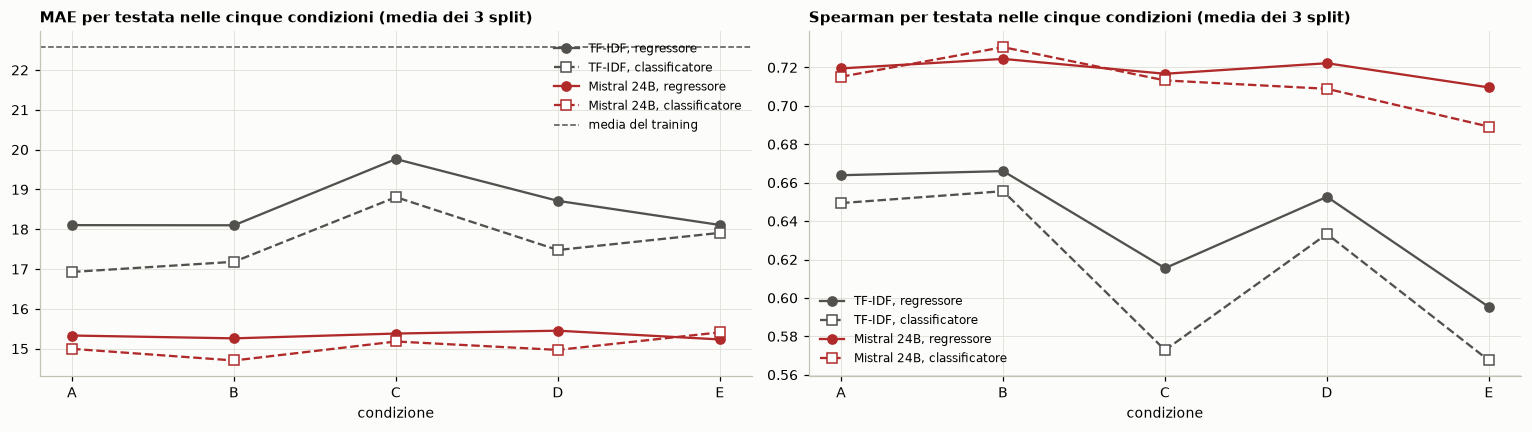

{'A': 'tutti gli articoli', 'B': 'tutti gli articoli, ogni testata pesa uguale', 'C': 'al più 10 articoli per testata', 'D': 'al più 30 articoli per testata', 'E': 'un vettore per testata (media degli articoli)'}


In [6]:
fig, assi = plt.subplots(1, 2, figsize=(14, 4))
for ax, m_ in zip(assi, ["MAE", "Spearman"]):
    for i, mod in enumerate(["TF-IDF", "Mistral 24B"]):
        for tipo, stile in [("regressore", "o-"), ("classificatore", "s--")]:
            try:
                v = [sintesi.loc[(mod, tipo, c, "testata"), (m_, "mean")] for c in P.CONDIZIONI]
            except KeyError:
                continue
            ax.plot(list(P.CONDIZIONI), v, stile, color=COLORE[mod], label=f"{mod}, {tipo}", mfc="white" if tipo == "classificatore" else COLORE[mod])
    if m_ == "MAE": ax.axhline(sintesi.loc[("media del training", "-", "-", "testata"), ("MAE", "mean")], color=GRIGIO, ls="--", lw=1, label="media del training")
    ax.set_title(f"{m_} per testata nelle cinque condizioni (media dei 3 split)"); ax.set_xlabel("condizione"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "regressore_o_classificatore.png", dpi=170, bbox_inches="tight"); plt.show()
print({c: d for c, d in P.CONDIZIONI.items()})

## 3. Le migliori configurazioni, con gli intervalli al 95%
Per ogni modello la configurazione con l'errore medio per testata più basso (split 1), con gli intervalli bootstrap sulle
testate, e la differenza dalla media del training.

In [7]:
s1 = mis[(mis.split == "split1") & (mis["unità"] == "testata")]
migliori = s1[s1.modello != "media del training"].sort_values("MAE").groupby("modello").head(1)
scelte = [tuple(r) for r in migliori[["modello", "tipo", "condizione"]].to_numpy()] + [("media del training", "-", "-")]
rng = np.random.default_rng(0)
dominii = t.index[split.split1.notna()]
campioni = [rng.choice(len(t), len(t)) for _ in range(B)]
righe = []
for cfg in scelte:
    g = pt[(pt.modello == cfg[0]) & (pt.tipo == cfg[1]) & (pt.condizione == cfg[2]) & (pt.split == "split1")].set_index("domain").reindex(t.index)
    v = P.misure(g.vero, g.previsione); bb = pd.DataFrame([P.misure(g.vero.iloc[i], g.previsione.iloc[i]) for i in campioni])
    righe.append({"configurazione": " · ".join(cfg), **{k_: f"{v[k_]:.2f} [{np.percentile(bb[k_], 2.5):.2f}; {np.percentile(bb[k_], 97.5):.2f}]" for k_ in v}})
pd.DataFrame(righe).set_index("configurazione")

,MAE,RMSE,R²,Spearman,Pearson
configurazione,,,,,
Mistral 24B · classificatore · C,14.70 [13.19; 16.29],19.18 [17.32; 21.25],0.50 [0.41; 0.57],0.73 [0.66; 0.78],0.72 [0.65; 0.78]
DeBERTa · regressore · B,16.47 [14.74; 18.54],22.31 [19.91; 25.06],0.32 [0.21; 0.42],0.66 [0.58; 0.73],0.61 [0.52; 0.70]
TF-IDF · classificatore · A,16.84 [15.38; 18.53],21.09 [19.23; 23.16],0.39 [0.31; 0.46],0.66 [0.58; 0.72],0.65 [0.57; 0.72]
ModernBERT · regressore · C,17.12 [15.55; 18.95],21.68 [19.78; 23.87],0.36 [0.27; 0.43],0.64 [0.56; 0.72],0.62 [0.53; 0.70]
media del training · - · -,22.57 [20.71; 24.57],27.05 [24.92; 29.32],-0.00 [-0.02; 0.00],-0.02 [-0.14; 0.11],-0.01 [-0.14; 0.12]


## 4. Dove si sbaglia: l'errore per fascia del punteggio vero
Per le migliori configurazioni: l'errore medio con il segno (previsto − vero: sopra lo zero = sovrastima) e l'errore
medio assoluto, nelle fasce del punteggio vero. Un regressore che si schiaccia verso la media sovrastima le testate
peggiori e sottostima le migliori.

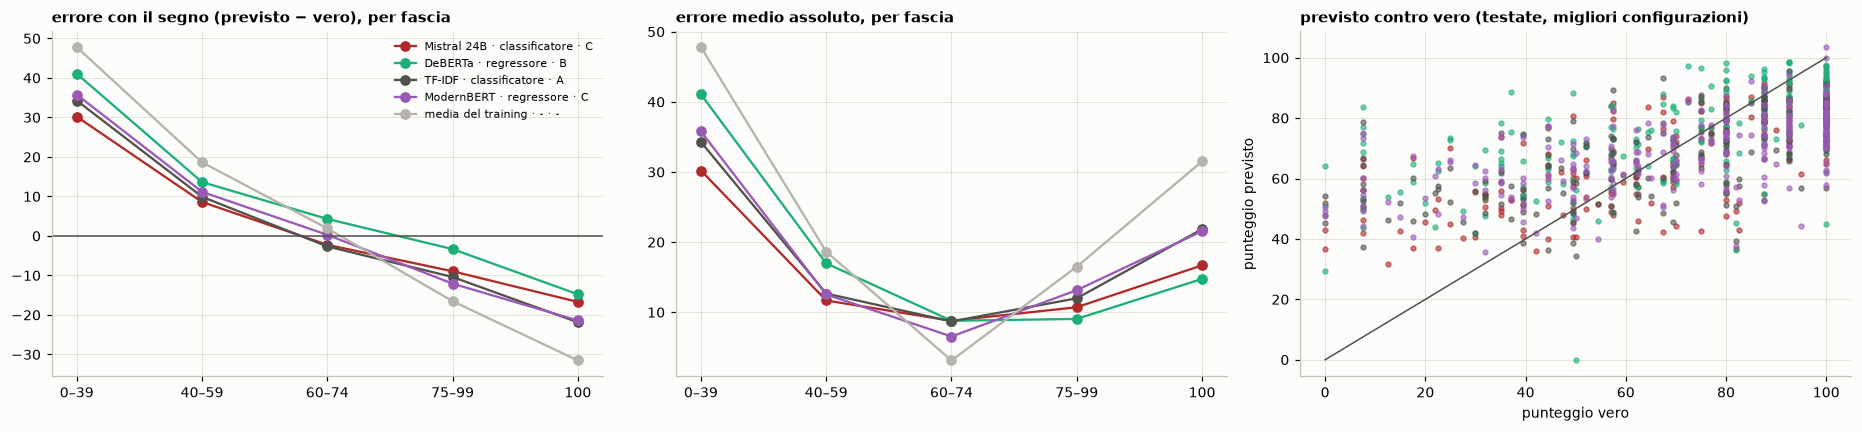

testate per fascia: {'0–39': 35, '40–59': 43, '60–74': 30, '75–99': 79, '100': 39}


In [8]:
FASCE = pd.cut(t.score, [-1, 39, 59, 74, 99, 100], labels=["0–39", "40–59", "60–74", "75–99", "100"])
fig, assi = plt.subplots(1, 3, figsize=(17, 4))
for cfg in scelte:
    g = pt[(pt.modello == cfg[0]) & (pt.tipo == cfg[1]) & (pt.condizione == cfg[2]) & (pt.split == "split1")].set_index("domain").reindex(t.index)
    e = g.previsione - g.vero
    assi[0].plot(FASCE.cat.categories, e.groupby(FASCE).mean(), "o-", color=COLORE.get(cfg[0], BLU), label=" · ".join(cfg))
    assi[1].plot(FASCE.cat.categories, e.abs().groupby(FASCE).mean(), "o-", color=COLORE.get(cfg[0], BLU))
    if cfg[0] != "media del training":
        assi[2].scatter(g.vero, g.previsione, s=10, alpha=0.6, color=COLORE.get(cfg[0], BLU))
assi[0].axhline(0, color=GRIGIO, lw=1); assi[0].set_title("errore con il segno (previsto − vero), per fascia"); assi[0].legend(fontsize=7)
assi[1].set_title("errore medio assoluto, per fascia")
assi[2].plot([0, 100], [0, 100], color=GRIGIO, lw=1); assi[2].set_title("previsto contro vero (testate, migliori configurazioni)")
assi[2].set_xlabel("punteggio vero"); assi[2].set_ylabel("punteggio previsto")
plt.tight_layout(); plt.savefig(OUT / "errore_per_fascia.png", dpi=170, bbox_inches="tight"); plt.show()
print("testate per fascia:", FASCE.value_counts().sort_index().to_dict())

## 5. Il DNA in punti: quanti articoli servono?
Per le migliori configurazioni (split 1): la testata giudicata con la media dei punteggi di **k articoli presi a caso**
(1, 3, 5, 9, 15, 25 o tutti). Con k = 1 è il giudizio di un solo articolo. Ogni punto è la media di 100 estrazioni.

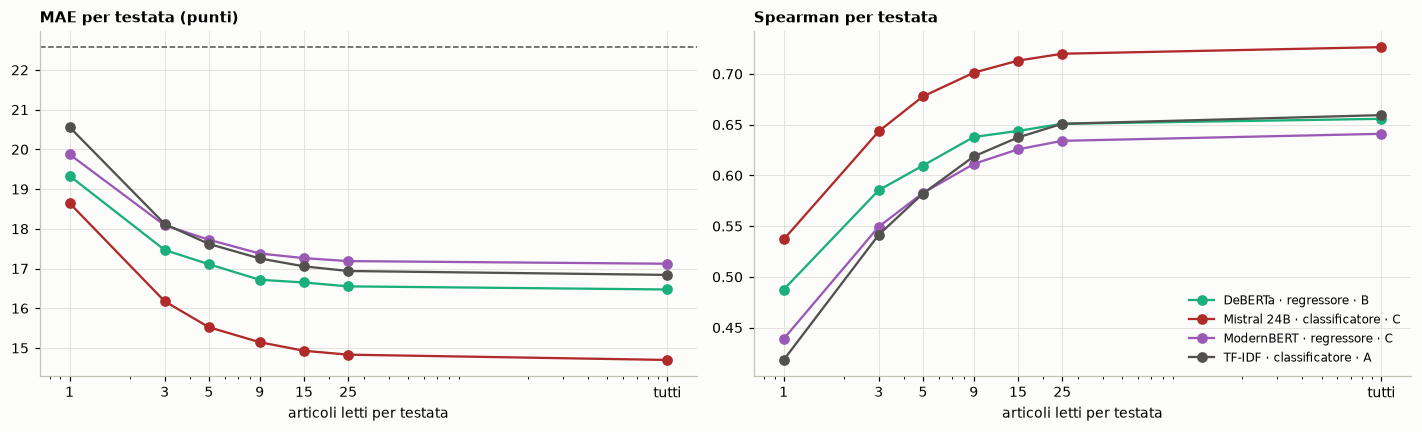

In [9]:
K = [1, 3, 5, 9, 15, 25, None]
curva = []
for cfg in scelte:
    if cfg[0] == "media del training" or cfg[2] == "E":
        continue
    g = pa[(pa.modello == cfg[0]) & (pa.tipo == cfg[1]) & (pa.condizione == cfg[2]) & (pa.split == "split1")]
    gruppi = [v.to_numpy() for _, v in g.groupby("domain").previsione]
    veri = g.groupby("domain").vero.first().to_numpy()
    for k in K:
        for _ in range(R if k else 1):
            p_ = np.array([v.mean() if not k or k >= len(v) else rng.choice(v, k, replace=False).mean() for v in gruppi])
            curva.append({"configurazione": " · ".join(cfg), "k": k or 999, **P.misure(veri, p_)})
curva = pd.DataFrame(curva).groupby(["configurazione", "k"]).mean().reset_index(); curva.to_csv(OUT / "curva_articoli.csv", index=False)
fig, assi = plt.subplots(1, 2, figsize=(13, 4))
for c, d in curva.groupby("configurazione"):
    for ax, m_ in zip(assi, ["MAE", "Spearman"]):
        ax.plot(d.k, d[m_], "o-", color=COLORE.get(c.split(" · ")[0], BLU), label=c)
for ax, m_ in zip(assi, ["MAE", "Spearman"]):
    ax.set_xscale("log"); ax.set_xticks([1, 3, 5, 9, 15, 25, 999], ["1", "3", "5", "9", "15", "25", "tutti"]); ax.set_xlabel("articoli letti per testata")
    ax.set_title(f"{m_} per testata" + (" (punti)" if m_ == "MAE" else ""))
assi[0].axhline(sintesi.loc[("media del training", "-", "-", "testata"), ("MAE", "mean")], color=GRIGIO, ls="--", lw=1)
assi[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "dna_punti.png", dpi=170, bbox_inches="tight"); plt.show()

## 6. Quanto conta lo split
Per i modelli lineari, l'errore medio per testata in ognuno dei 3 split: se le linee sono piatte, i risultati non
dipendono dallo split.

In [10]:
d = mis[(mis["unità"] == "testata") & mis.modello.isin(["TF-IDF", "Mistral 24B"])]
piv = d.pivot_table(index=["modello", "tipo", "condizione"], columns="split", values="MAE")
display(piv.round(2))
print("differenza media tra lo split migliore e il peggiore:", round((piv.max(axis=1) - piv.min(axis=1)).mean(), 2), "punti")

split                                  split1  split2  split3
modello     tipo           condizione                        
Mistral 24B classificatore A            15.04   14.90   15.06
                           B            14.71   14.56   14.85
                           C            14.70   14.92   15.93
                           D            14.71   15.00   15.21
                           E            15.35   15.05   15.83
            regressore     A            15.33   15.14   15.53
                           B            15.05   15.27   15.47
                           C            15.07   15.29   15.79
                           D            15.55   15.41   15.40
                           E            14.97   14.94   15.79
TF-IDF      classificatore A            16.84   16.52   17.42
                           B            16.91   16.80   17.85
                           C            18.60   18.60   19.23
                           D            17.22   17.23   17.98
                           E            17.55   17.69   18.49
            regressore     A            17.97   17.96   18.39
                           B            17.93   18.01   18.36
                           C            19.66   19.70   19.93
                           D            18.49   18.65   19.01
                           E            17.89   17.81   18.63

differenza media tra lo split migliore e il peggiore: 0.61 punti
